# Discrete and smeared stringers: cylinders with riveted Z stringers (Peterson and Dow 1959; Card and Jones 1966)

Peterson and Dow [1] tested in axial compression 7075-T6 cylinders stiffened
by Z-section stringers riveted inside the skin, 1.25 in apart; Card and Jones
[2] tested the same cylinders with the stringers outside and list both series
in their Table I (p. 7): cylinders 5, 7, 9, 11 (external) and 6, 8, 10, 12
(internal, from [1]), with the test loads and the loads of their
smeared-stiffener theory for clamped ($\bar{N}_c$) and simply supported
($\bar{N}_s$) ends. This notebook builds the cylinders as `MultiDomain`
assemblies with discrete stringers and compares with these values, to
quantify the gap between discrete and smeared stringers at a spacing of 1.25
in (the integral blade cylinders 1 to 4 of [2], 1.0 in apart, are in
`card1966_blade_cylinder_buckling.ipynb`).

A stringer is represented by one plate strip normal to the skin (a blade),
which cannot reproduce a Z section exactly; two equivalent blades are used,
and the discrete model and the smeared theory are both evaluated for each,
so that the discreteness gap (discrete against smeared, same blade) is
separated from the effect of replacing the Z by a blade.

[1] J. P. Peterson and M. B. Dow, *Compression tests on circular cylinders
stiffened longitudinally by closely spaced Z-section stringers*, NASA Memo
2-12-59L, March 1959.

[2] M. F. Card and R. M. Jones, *Experimental and theoretical results for
buckling of eccentrically stiffened cylinders*, NASA TN D-3639, October 1966,
https://ntrs.nasa.gov/citations/19660027866.

[3] D. L. Block, M. F. Card and M. M. Mikulas, Jr., *Buckling of eccentrically
stiffened orthotropic cylinders*, NASA TN D-2960, 1965,
https://ntrs.nasa.gov/citations/19650021133.

In [1]:
%matplotlib inline
import time

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

import blade_cylinder_utils as bu
import stringer_cylinder_utils as su


def pct(value, ref):
    return 100*(value/ref - 1)


def table(header, rows):
    out = ['| ' + ' | '.join(header) + ' |', '|' + '---|'*len(header)]
    out += ['| ' + ' | '.join(str(c) for c in row) + ' |' for row in rows]
    display(Markdown('\n'.join(out)))

def plot_mode(ax, md_, c, skin, R, title, ns, frac=1.):
    x, th, w = bu.skin_w(md_, c, skin, R)
    sel = th <= frac*th.max() + 1e-12
    ax.pcolormesh(np.degrees(th[sel]), x, (w[sel]/np.abs(w).max()).T, cmap='RdBu_r',
                  shading='auto', vmin=-1, vmax=1)
    pos = (np.arange(ns) + 0.5)*2*np.pi/ns
    pos = pos[pos <= th[sel].max()]
    ax.plot(np.degrees(pos), np.zeros_like(pos), 'k.', ms=3)
    ax.set_title(title, fontsize=9)
    ax.set_xlabel(r'$\theta$, deg')

from scipy.optimize import brentq

## Cylinders and the Z section

Table I(a) of [2] (p. 7), $R = 15.92$ in, $E = 10.5 \times 10^3$ ksi, $\mu =
0.32$, 80 stringers 1.25 in apart (Fig. 2(a)); ends ground flat between the
platens (clamped). $\bar{N}$ in lb/in ($\bar{P}_e/(2\pi R)$; the columns are
headed kips/in.). Cylinders 6, 8, 10, 12 of [2] are specimens 6, 5, 3, 4 of
[1], where $R = 15.80$ in and $E = 10\,900$ ksi are printed; the values of
[2] are used.

The Z (Fig. 2(a) of [2], Fig. 2(b) of [1]): sheet 0.040 in, bend radius
0.04 in, depth 0.54 in from the skin surface, attached flange 0.375 in and
free flange 0.22 in overall, nominal dimensions. Its section is computed on
the centre line of the sheet with the two bends (the reading that reproduces
$\bar{N}_c$ and $\bar{N}_s$ of [2] best; the reading with square corners is
compared in the bfsccylinder implementation of this case), $J = \sum b
t^3/3$. Equivalent blades on the skin: **A-z** (same area and centroid) and
**A-Io** (same area and moment of inertia about the middle surface of the
skin). In the model the blade is the plate strip from the middle surface of
the skin to the tip, $H_s = h_b + t/2$, with $D_{66}$ scaled to $G J$ of the
Z; the smeared reference of the gap is equation (15) of [3] for the strip as
modelled ($A = t_b H_s$, $\bar{z} = \pm H_s/2$, $I_o = t_b H_s^3/3$).

In [2]:
E_PSI, MU, R, NS = 10.5e6, 0.32, 15.92, 80
LBF, IN = bu.LBF, bu.IN
E = E_PSI*bu.PSI
d = 2*np.pi*R/NS
CYL = {5: ('external', .0410, 59.00, 1696, 2289, 1193), 6: ('internal', .0401, 59.00, 995, 1174, 766),
       7: ('external', .0391, 41.83, 1863, 2617, 1283), 8: ('internal', .0401, 41.83, 1260, 1383, 773),
       9: ('external', .0392, 29.68, 2730, 3426, 1574), 10: ('internal', .0403, 29.68, 1710, 1813, 838),
       11: ('external', .0395, 20.77, 3780, 4947, 2068), 12: ('internal', .0401, 20.77, 2730, 2845, 1027)}
TZ, RB, HZ, BB, BT = 0.040, 0.04, 0.54, 0.375, 0.22


def z_section(t, side):
    # centre line of the Z with the two bends, z from the skin surface (in)
    rc = RB + TZ/2
    zb, zt = TZ/2, HZ - TZ/2
    a = np.linspace(0, np.pi/2, 41)[:-1] + np.pi/160
    lw = zt - zb - 2*rc
    ds = np.concatenate([[BB - TZ/2 - rc], np.full(40, rc*np.pi/80), np.full(40, lw/40),
                         np.full(40, rc*np.pi/80), [BT - TZ/2 - rc]])
    z = np.concatenate([[zb], zb + rc - rc*np.cos(a), zb + rc + (np.arange(40) + 0.5)*lw/40,
                        zt - rc + rc*np.sin(a), [zt]])
    A = TZ*ds.sum()
    zc = (TZ*ds*z).sum()/A
    Ic = (TZ*ds*(z - zc)**2).sum() + TZ**3/12*(BB + BT)
    sign = 1. if side == 'external' else -1.
    zs = sign*(t/2 + zc)
    return dict(A=A, zc=zc, Io=Ic + A*zs**2, J=ds.sum()*TZ**3/3)


def strips(t, side):
    zz = z_section(t, side)
    sign = 1. if side == 'external' else -1.
    out = {}
    hbs = {'A-z': 2*zz['zc'],
           'A-Io': brentq(lambda hb: zz['A']*hb**2/12 + zz['A']*((t + hb)/2)**2 - zz['Io'], 0.05, 2.)}
    for k, hb in hbs.items():
        tb = zz['A']/hb
        Hs = hb + t/2
        out[k] = dict(tb=tb, hb=hb, Hs=Hs, J=zz['J'], Jplate=Hs*tb**3/3,
                      sec=(tb*Hs, sign*Hs/2, tb*Hs**3/3, zz['J']))
    return zz, out


rows = []
Z, STRIPS = {}, {}
for c, (side, t, L, Ne, Nc, Ns) in CYL.items():
    Z[c], STRIPS[c] = strips(t, side)
    zz = Z[c]
    Nz = su.smeared_ss(R, L, t, E_PSI, MU, d, zz['A'], (1 if side == 'external' else -1)*(t/2 + zz['zc']),
                       zz['Io'], zz['J'], nmax=40)
    row = [c, side, Ne, Nc, Ns, '%.0f %s, %+.1f %%' % (Nz[0], Nz[1], pct(Nz[0], Ns))]
    for k, s in STRIPS[c].items():
        s['smSS'] = su.smeared_ss(R, L, t, E_PSI, MU, d, *s['sec'], nmax=40)
        row.append('%.4f x %.4f; %.0f, %+.1f %%' % (s['tb'], s['hb'], s['smSS'][0], pct(s['smSS'][0], Nz[0])))
    rows.append(row)
print('Z: A = %.5f in^2, centroid %.4f in above the skin, J = %.3e in^4'
      % (Z[5]['A'], Z[5]['zc'], Z[5]['J']))
table(['cyl.', 'stringers', 'test N_e', 'N_c', 'N_s', 'Eq. (15), Z, vs N_s',
       'blade A-z: t_b x h_b, in; Eq. (15) vs Z', 'blade A-Io: t_b x h_b, in; Eq. (15) vs Z'], rows)

Z: A = 0.04014 in^2, centroid 0.2314 in above the skin, J = 2.141e-05 in^4


| cyl. | stringers | test N_e | N_c | N_s | Eq. (15), Z, vs N_s | blade A-z: t_b x h_b, in; Eq. (15) vs Z | blade A-Io: t_b x h_b, in; Eq. (15) vs Z |
|---|---|---|---|---|---|---|---|
| 5 | external | 1696 | 2289 | 1193 | 1193 (1, 6), -0.0 % | 0.0867 x 0.4628; 1178, -1.2 % | 0.0763 x 0.5263; 1223, +2.5 % |
| 6 | internal | 995 | 1174 | 766 | 765 (1, 6), -0.2 % | 0.0867 x 0.4628; 750, -1.9 % | 0.0763 x 0.5263; 745, -2.5 % |
| 7 | external | 1863 | 2617 | 1283 | 1281 (1, 7), -0.1 % | 0.0867 x 0.4628; 1245, -2.8 % | 0.0762 x 0.5264; 1320, +3.0 % |
| 8 | internal | 1260 | 1383 | 773 | 772 (1, 7), -0.1 % | 0.0867 x 0.4628; 737, -4.6 % | 0.0763 x 0.5263; 742, -3.9 % |
| 9 | external | 2730 | 3426 | 1574 | 1572 (1, 9), -0.1 % | 0.0867 x 0.4628; 1492, -5.1 % | 0.0763 x 0.5264; 1612, +2.5 % |
| 10 | internal | 1710 | 1813 | 838 | 836 (1, 8), -0.2 % | 0.0867 x 0.4628; 760, -9.1 % | 0.0763 x 0.5263; 788, -5.7 % |
| 11 | external | 3780 | 4947 | 2068 | 2066 (1, 10), -0.1 % | 0.0867 x 0.4628; 1898, -8.1 % | 0.0763 x 0.5264; 2117, +2.5 % |
| 12 | internal | 2730 | 2845 | 1027 | 1025 (1, 9), -0.2 % | 0.0867 x 0.4628; 863, -15.8 % | 0.0763 x 0.5263; 946, -7.7 % |

## Model with discrete stringers and convergence

`su.buckling_membrane`: half cylinder (40 skin bays between symmetry planes,
40 `plate_clpt_gl` blades), membrane pre-buckling state of the smeared theory,
both ends clamped (`'CC'`, $u = v = w = w_{,x} = 0$ on skin and blades) or
simply supported (`'SS'`, $N_x = v = w = M_x = 0$). The rivets, the attached
flange and the lap joints are not represented. The smeared clamped value of
each strip is not computed here (the Galerkin solution of [2] is in the
bfsccylinder implementation of this case); the clamped results are compared
with $\bar{N}_c$ and the test. Convergence for the longest and the shortest
cylinder, blade A-z:

In [3]:
LEVELS = [(10, 4, 4), (14, 6, 4), (18, 8, 5)]


def run(c, blade, bc, lev):
    side, t, L = CYL[c][:3]
    s = STRIPS[c][blade]
    N, modes, N1, md_, skin, ndof, dt = su.buckling_membrane(
        R*IN, t*IN, L*IN, E, MU, s['tb']*IN, s['Hs']*IN, side, bc, NS, *lev,
        D66_factor=s['J']/s['Jplate'])
    return N/(LBF/IN), modes, md_, skin, ndof, dt


t0 = time.time()
rows = []
for c in (6, 11):
    for bc in ('CC', 'SS'):
        prev = None
        for lev in LEVELS:
            N, modes, md_, skin, ndof, dt = run(c, 'A-z', bc, lev)
            rows.append([c, bc, lev, ndof, '%.1f' % dt, '%.1f' % N, '(%d, %d)' % modes[0][1:3],
                         '' if prev is None else '%+.2f %%' % pct(N, prev)])
            prev = N
table(['cyl.', 'ends', 'm_x, n_y, n_b', 'dofs', 'time, s', 'N, lb/in', '(m, n)', 'change'], rows)
print('%.0f s' % (time.time() - t0))

| cyl. | ends | m_x, n_y, n_b | dofs | time, s | N, lb/in | (m, n) | change |
|---|---|---|---|---|---|---|---|
| 6 | CC | (10, 4, 4) | 7480 | 2.7 | 968.4 | (2, 8) |  |
| 6 | CC | (14, 6, 4) | 13364 | 4.7 | 966.6 | (2, 8) | -0.18 % |
| 6 | CC | (18, 8, 5) | 23280 | 14.8 | 966.1 | (2, 8) | -0.06 % |
| 6 | SS | (10, 4, 4) | 6839 | 3.0 | 702.3 | (1, 6) |  |
| 6 | SS | (14, 6, 4) | 12723 | 6.4 | 702.2 | (1, 6) | -0.01 % |
| 6 | SS | (18, 8, 5) | 22639 | 19.9 | 702.2 | (1, 6) | -0.00 % |
| 11 | CC | (10, 4, 4) | 7480 | 3.2 | 4123.1 | (1, 12) |  |
| 11 | CC | (14, 6, 4) | 13364 | 6.6 | 3791.4 | (8, 40) | -8.04 % |
| 11 | CC | (18, 8, 5) | 23280 | 23.0 | 3482.1 | (10, 40) | -8.16 % |
| 11 | SS | (10, 4, 4) | 6839 | 3.3 | 1866.0 | (1, 10) |  |
| 11 | SS | (14, 6, 4) | 12723 | 7.4 | 1865.5 | (1, 10) | -0.02 % |
| 11 | SS | (18, 8, 5) | 22639 | 41.4 | 1865.4 | (1, 10) | -0.00 % |

136 s


## Discrete against smeared stringers and the tests

Finest level; "gap SS" is the discrete simply supported model against
equation (15) of the same strip.

In [4]:
t0 = time.time()
RES = {}
for c in CYL:
    for blade in ('A-z', 'A-Io'):
        for bc in ('CC', 'SS'):
            RES[(c, blade, bc)] = run(c, blade, bc, LEVELS[-1])
print('%.0f s' % (time.time() - t0))
rows = []
for c, (side, t, L, Ne, Nc, Ns) in CYL.items():
    for blade in ('A-z', 'A-Io'):
        Ncc, mcc = RES[(c, blade, 'CC')][:2]
        Nss, mss = RES[(c, blade, 'SS')][:2]
        sm = STRIPS[c][blade]['smSS'][0]
        rows.append([c, side, blade, '%.0f (%d, %d)' % (Ncc, *mcc[0][1:3]), '%+.1f %%' % pct(Ncc, Nc),
                     '%+.1f %%' % pct(Ncc, Ne), '%.0f (%d, %d)' % (Nss, *mss[0][1:3]),
                     '**%+.1f %%**' % pct(Nss, sm), '%+.1f %%' % pct(Nss, Ns)])
table(['cyl.', 'stringers', 'blade', 'discrete CC (m, n)', 'vs N_c', 'vs N_e (test)',
       'discrete SS (m, n)', 'gap SS', 'vs N_s'], rows)

604 s


| cyl. | stringers | blade | discrete CC (m, n) | vs N_c | vs N_e (test) | discrete SS (m, n) | gap SS | vs N_s |
|---|---|---|---|---|---|---|---|---|
| 5 | external | A-z | 2164 (1, 7) | -5.5 % | +27.6 % | 1145 (1, 6) | **-2.8 %** | -4.0 % |
| 5 | external | A-Io | 2305 (1, 7) | +0.7 % | +35.9 % | 1189 (1, 6) | **-2.7 %** | -0.3 % |
| 6 | internal | A-z | 966 (2, 8) | -17.7 % | -2.9 % | 702 (1, 6) | **-6.4 %** | -8.3 % |
| 6 | internal | A-Io | 1029 (2, 8) | -12.4 % | +3.4 % | 696 (1, 6) | **-6.7 %** | -9.2 % |
| 7 | external | A-z | 2392 (1, 9) | -8.6 % | +28.4 % | 1223 (1, 7) | **-1.8 %** | -4.7 % |
| 7 | external | A-Io | 2615 (1, 9) | -0.1 % | +40.4 % | 1296 (1, 7) | **-1.8 %** | +1.0 % |
| 8 | internal | A-z | 1162 (1, 8) | -16.0 % | -7.8 % | 698 (1, 7) | **-5.3 %** | -9.7 % |
| 8 | internal | A-Io | 1225 (1, 8) | -11.4 % | -2.8 % | 700 (1, 7) | **-5.6 %** | -9.4 % |
| 9 | external | A-z | 3012 (1, 10) | -12.1 % | +10.3 % | 1468 (1, 9) | **-1.6 %** | -6.7 % |
| 9 | external | A-Io | 3233 (12, 40) | -5.6 % | +18.4 % | 1584 (1, 9) | **-1.7 %** | +0.6 % |
| 10 | internal | A-z | 1424 (1, 9) | -21.5 % | -16.7 % | 725 (1, 8) | **-4.5 %** | -13.4 % |
| 10 | internal | A-Io | 1584 (1, 9) | -12.6 % | -7.3 % | 750 (1, 8) | **-4.9 %** | -10.5 % |
| 11 | external | A-z | 3482 (10, 40) | -29.6 % | -7.9 % | 1865 (1, 10) | **-1.7 %** | -9.8 % |
| 11 | external | A-Io | 3066 (10, 40) | -38.0 % | -18.9 % | 2074 (1, 10) | **-2.0 %** | +0.3 % |
| 12 | internal | A-z | 2066 (1, 10) | -27.4 % | -24.3 % | 828 (1, 9) | **-4.0 %** | -19.3 % |
| 12 | internal | A-Io | 2431 (1, 10) | -14.5 % | -10.9 % | 904 (1, 9) | **-4.5 %** | -12.0 % |

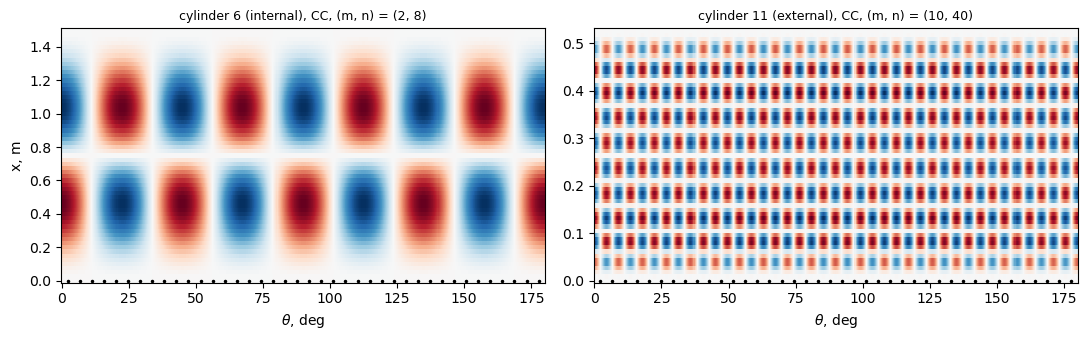

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, c in zip(axes, (6, 11)):
    N, modes, md_, skin = RES[(c, 'A-z', 'CC')][:4]
    plot_mode(ax, md_, modes[0][3], skin, R*IN, 'cylinder %d (%s), CC, (m, n) = (%d, %d)'
              % (c, CYL[c][0], *modes[0][1:3]), NS)
axes[0].set_ylabel('x, m')
plt.tight_layout()
plt.show()

## Discussion

- **The Z section.** Read on the centre line of the sheet with its two bends,
  the nominal Z reproduces $\bar{N}_s$ of Card and Jones within 0.2 % with
  equation (15) (the clamped Galerkin solution and the reading with square
  corners, 0.4 to 5.0 % higher, are in the bfsccylinder implementation).
- **Equivalent blades.** Replacing the Z by a blade changes the smeared
  simply supported load by -15.8 to +3.0 %: more than the discreteness
  effect, which is why the gap is measured against the same strip.
- **Discreteness gap**, simply supported, general modes: -1.6 to -2.8 %
  (external) and -4.0 to -6.7 % (internal), the same within 0.4 % for both
  blades; larger for internal stringers. At 1.0 in spacing (card1966
  notebook), cylinder 4 (internal) gives -6.6 % against the strip as modelled.
- **Clamped, tests.** Card and Jones' tests are at 71 to 80 % (external) and
  85 to 96 % (internal) of $\bar{N}_c$. The blade A-Io reproduces $\bar{N}_c$
  within 0.8 % for the external cylinders 5 and 7; for the internal cylinders
  both blades are 11 to 27 % below $\bar{N}_c$.
- **Local buckling.** The model leaves the whole 1.25-in pitch of skin free;
  the riveted attached flange of the Z covers 0.375 in of it. For the
  shortest external cylinders the lowest clamped mode is local, one half-wave
  of skin per bay ($n = 40$): cylinder 11, 3482 lb/in (blade A-z) and 3066
  (A-Io), below the test (3780 lb/in, general mode $n_e = 8$), and cylinder 9
  with the blade A-Io, 3233 lb/in. These modes need more axial terms than the
  general ones (the convergence table for cylinder 11 changes by 8 % per step
  once the local mode appears) and are an artifact of the missing flange;
  the clamped values of cylinders 9 and 11 are not compared with the tests.
- **The bfsccylinder implementation of this case**
  (`bfsccylinder/notebooks/peterson1959_stiffened_cylinder_buckling.ipynb`:
  one stringer pitch with cyclic symmetry, the same Z, blades and twisting
  stiffness, harmonics $n \le 20$ plus a check of $n = 40$) agrees within
  0.6 % on the general modes, e.g. cylinder 6, blade A-z, clamped 968 and
  simply supported 703 lb/in (here 966 and 702); its gaps are -1.4 to -2.7 %
  (external) and -3.8 to -6.6 % (internal) simply supported, -1.6 to -3.5 %
  and -3.8 to -5.5 % clamped (against its Galerkin solution for the same
  strip). Its local check of cylinder 11 gives 3424 lb/in at $n = 40$ with
  4 nodes per inch.
- **Not modelled**: rivets, lap joints, the Z as three plates (attached
  flange, web, free flange), its product of inertia, plasticity.